# 02 — Predicting outage severity (Objective 1)

**Target:** peak % of customers out per (storm episode, county), as `log(1 + percent)` for regression and low (<1%) / medium (1–10%) / high (≥10%) for classification.
**Split:** train 2014–2019, validate 2020 (tuning / early stopping), test 2021–2022.
**Models:** storm-type baseline → linear / logistic → random forest → LightGBM. **SHAP** explains the LightGBM regressor.

In [1]:
# Works on Colab (Drive) or locally (repo checkout)
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
try:
    if os.environ.get("LIGHTSOUT_PROJECT"):  # a repo checkout, e.g. run with nbconvert inside Colab
        raise ImportError
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = pathlib.Path("/content/drive/MyDrive/LightsOut")
    ZIP = pathlib.Path("/content/drive/MyDrive/LightsOut_code.zip")
    if ZIP.exists():  # refresh code (src/, notebooks/) from the latest uploaded zip; data/ is untouched
        import zipfile; zipfile.ZipFile(ZIP).extractall(PROJECT)
    !pip -q install polars lifelines scikit-survival shap geopandas lightgbm
except ImportError:
    PROJECT = pathlib.Path(os.environ["LIGHTSOUT_PROJECT"]) if os.environ.get("LIGHTSOUT_PROJECT") else \
        pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
os.chdir(PROJECT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lightsout import config as C, viz
viz.setup()
df = pd.read_parquet(C.PROCESSED / "model_table.parquet")
print(f"{len(df):,} (storm episode, county) units, {df.fips.nunique():,} counties, years {df.year.min()}-{df.year.max()}")

226,389 (storm episode, county) units, 3,037 counties, years 2014-2022


In [2]:
from lightsout import models_severity as S
print(df.groupby("split")["severity"].value_counts(normalize=True).unstack().round(3))
fit = S.fit_all(df)

severity    low  medium   high
split                         
test      0.719   0.205  0.076
train     0.761   0.182  0.058
val       0.700   0.214  0.086


In [3]:
res_val, res_test = S.results_table(fit, "val"), S.results_table(fit, "test")
res_test.to_csv(C.REPORTS / "severity_results_test.csv")
(C.REPORTS / "severity_results_test.md").write_text(res_test.to_markdown())
res_val.to_csv(C.REPORTS / "severity_results_val.csv")
print("LightGBM trees (stage 1 early-stopped / final refit):", fit["n_iter"])
print("Decision weights for F1-tuned cutoffs (fit on 2020):", fit["decision_weights"])
print("Validation (2020, models trained 2014-2019)"); display(res_val)
print("Test (2021-2022, models refit on 2014-2020)"); display(res_test)

LightGBM trees (stage 1 early-stopped / final refit): {'stage1': {'reg': 815, 'clf': 2196}, 'final': {'reg': 986, 'clf': 2656}}
Decision weights for F1-tuned cutoffs (fit on 2020): {'high': np.float64(1.1), 'low': np.float64(1.0), 'medium': np.float64(1.1)}
Validation (2020, models trained 2014-2019)


,RMSE (log),MAE (log),MAE (pct pts),macro F1,accuracy,recall low,recall medium,recall high
model,,,,,,,,
Baseline (storm type),0.950,0.682,3.284,0.345,0.706,0.993,0.000,0.130
Linear / logistic,0.870,0.604,3.123,0.516,0.616,0.653,0.491,0.622
Random forest,0.853,0.578,3.065,0.554,0.713,0.825,0.504,0.322
LightGBM,0.845,0.562,3.025,0.568,0.731,0.862,0.451,0.358
LightGBM (F1-tuned cutoffs),NaN,NaN,NaN,0.568,0.726,0.846,0.476,0.364
LightGBM (high-recall cutoff),NaN,NaN,NaN,0.565,0.718,0.845,0.390,0.500


Test (2021-2022, models refit on 2014-2020)


,RMSE (log),MAE (log),MAE (pct pts),macro F1,accuracy,recall low,recall medium,recall high
model,,,,,,,,
Baseline (storm type),0.941,0.667,2.948,0.296,0.719,0.997,0.000,0.028
Linear / logistic,0.857,0.593,2.799,0.510,0.633,0.686,0.465,0.586
Random forest,0.841,0.568,2.745,0.544,0.727,0.852,0.453,0.295
LightGBM,0.830,0.551,2.700,0.553,0.740,0.878,0.410,0.328
LightGBM (F1-tuned cutoffs),NaN,NaN,NaN,0.556,0.736,0.863,0.436,0.338
LightGBM (high-recall cutoff),NaN,NaN,NaN,0.552,0.728,0.861,0.357,0.465


### Uncertainty, per-class performance and hyperparameters
Cluster bootstrap over storm episodes (500 resamples) gives 95% intervals for the test metrics.

In [4]:
ci = S.bootstrap_ci(fit, "test", n_boot=500)
ci.to_csv(C.REPORTS / "severity_ci_test.csv"); (C.REPORTS / "severity_ci_test.md").write_text(ci.to_markdown())
ci

,RMSE (log) 95% CI,macro F1 95% CI,accuracy 95% CI
model,,,
Baseline (storm type),"[0.921, 0.957]","[0.289, 0.305]","[0.712, 0.726]"
Linear / logistic,"[0.840, 0.871]","[0.503, 0.517]","[0.626, 0.640]"
Random forest,"[0.824, 0.856]","[0.535, 0.552]","[0.722, 0.734]"
LightGBM,"[0.814, 0.845]","[0.545, 0.561]","[0.734, 0.746]"
LightGBM (F1-tuned cutoffs),NaN,"[0.548, 0.564]","[0.730, 0.742]"
LightGBM (high-recall cutoff),NaN,"[0.544, 0.559]","[0.722, 0.734]"


In [5]:
pc = pd.concat({"LightGBM (argmax)": S.per_class_table(fit, "LightGBM|clf"),
                "LightGBM (F1-tuned cutoffs)": S.per_class_table(fit, "LightGBM (F1-tuned cutoffs)|clf"),
                "LightGBM (high-recall cutoff)": S.per_class_table(fit, "LightGBM (high-recall cutoff)|clf"),
                "Random forest": S.per_class_table(fit, "Random forest|clf")})
pc.to_csv(C.REPORTS / "severity_per_class_test.csv"); (C.REPORTS / "severity_per_class_test.md").write_text(pc.to_markdown())
pc

precision  recall     F1      n
LightGBM (argmax)             low         0.824   0.878  0.850  45435
                              medium      0.486   0.410  0.445  12958
                              high        0.411   0.328  0.365   4803
LightGBM (F1-tuned cutoffs)   low         0.829   0.863  0.846  45435
                              medium      0.474   0.436  0.454  12958
                              high        0.407   0.338  0.369   4803
LightGBM (high-recall cutoff) low         0.828   0.861  0.844  45435
                              medium      0.487   0.357  0.412  12958
                              high        0.348   0.465  0.398   4803
Random forest                 low         0.828   0.852  0.839  45435
                              medium      0.456   0.453  0.454  12958
                              high        0.395   0.295  0.338   4803

### Operating point for high-severity outages
Accuracy alone rewards predicting "low" (72% of test rows). We report how well the model ranks high-severity outages (AUC, average precision) and choose the cutoff on purpose: the smallest P(high) that catches 50% of 2020's high-severity outages, then apply it unchanged to 2021-22.

In [6]:
op = S.operating_table(fit)
op.to_csv(C.REPORTS / "severity_operating_point.csv"); (C.REPORTS / "severity_operating_point.md").write_text(op.to_markdown())
print("P(high) cutoff fit on 2020:", fit["high_cutoff"]); op

P(high) cutoff fit on 2020: 0.3084


split,val,test
high share,0.086,0.076
AUC (high vs rest),0.846,0.839
average precision (high),0.376,0.354
LightGBM: recall high,0.358,0.328
LightGBM: precision high,0.438,0.411
LightGBM (F1-tuned cutoffs): recall high,0.364,0.338
LightGBM (F1-tuned cutoffs): precision high,0.428,0.407
LightGBM (high-recall cutoff): recall high,0.500,0.465
LightGBM (high-recall cutoff): precision high,0.368,0.348


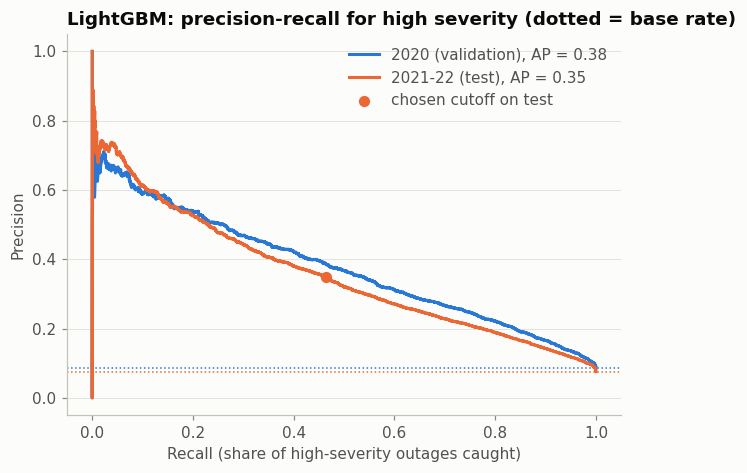

In [7]:
from sklearn.metrics import precision_recall_curve, average_precision_score
j = list(fit["classes"]).index("high")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (split, label), col in zip([("val", "2020 (validation)"), ("test", "2021-22 (test)")], viz.CATEGORICAL):
    y = fit["truth"][split].severity.astype(str).to_numpy() == "high"
    prec, rec, _ = precision_recall_curve(y, fit["proba"][split][:, j])
    ax.plot(rec, prec, color=col, label=f"{label}, AP = {average_precision_score(y, fit['proba'][split][:, j]):.2f}")
    ax.axhline(y.mean(), color=col, linestyle=":", linewidth=1)
yt = fit["truth"]["test"].severity.astype(str).to_numpy() == "high"
pt = fit["pred"]["test"]["LightGBM (high-recall cutoff)|clf"].astype(str).to_numpy() == "high"
ax.scatter([(pt & yt).sum() / yt.sum()], [(pt & yt).sum() / pt.sum()], color=viz.CATEGORICAL[1], zorder=3, s=40,
           label="chosen cutoff on test")
ax.set_xlabel("Recall (share of high-severity outages caught)"); ax.set_ylabel("Precision")
ax.set_title("LightGBM: precision-recall for high severity (dotted = base rate)"); ax.legend()
viz.save(fig, "06b_high_severity_pr_curve"); fig

In [8]:
hp = S.hyperparameter_table()
hp.to_csv(C.REPORTS / "hyperparameters_severity.csv", index=False)
(C.REPORTS / "hyperparameters_severity.md").write_text(hp.to_markdown(index=False))
hp

,model,hyperparameter,value
0,Baseline (storm type),rule,mean (regression) / most common class per stor...
1,Ridge,alpha,1000.0
2,Logistic,C,10.0
3,Logistic,class_weight,balanced
4,Logistic,max_iter,3000
5,Random forest (both),n_estimators,300
6,Random forest regressor,max_features,0.5
7,Random forest regressor,min_samples_leaf,6
8,Random forest regressor,max_depth,20
9,Random forest regressor,max_samples,0.35


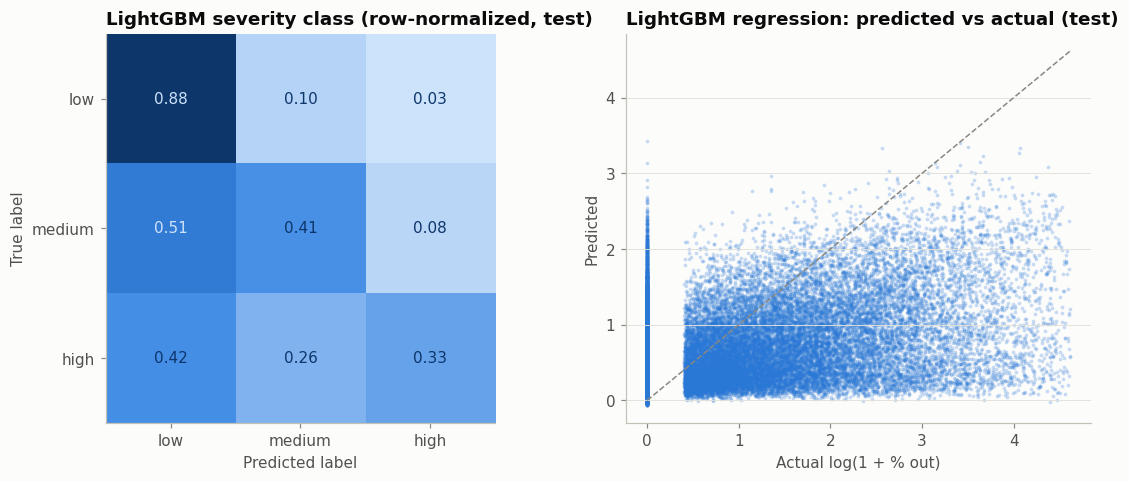

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
te = fit["truth"]["test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(te.severity.astype(str), fit["pred"]["test"]["LightGBM|clf"],
    labels=["low", "medium", "high"], normalize="true", cmap=viz.SEQUENTIAL_CMAP, ax=axes[0],
    values_format=".2f", colorbar=False)
axes[0].set_title("LightGBM severity class (row-normalized, test)"); axes[0].grid(False)
p = fit["pred"]["test"]["LightGBM|reg"]
axes[1].scatter(te.log_peak_pct, p, s=6, alpha=0.25, color=viz.CATEGORICAL[0], linewidths=0)
lim = [0, max(te.log_peak_pct.max(), p.max())]
axes[1].plot(lim, lim, color=viz.MUTED, linewidth=1, linestyle="--")
axes[1].set_xlabel("Actual log(1 + % out)"); axes[1].set_ylabel("Predicted")
axes[1].set_title("LightGBM regression: predicted vs actual (test)")
viz.save(fig, "06_severity_test_diagnostics"); fig

In [10]:
# per storm type: does the best model beat the baseline everywhere?
pt = fit["pred"]["test"]
by_type = pd.DataFrame({
    "n": te.groupby("storm_type").size(),
    "baseline MAE": (te.log_peak_pct - pt["Baseline (storm type)|reg"]).abs().groupby(te.storm_type).mean(),
    "LightGBM MAE": (te.log_peak_pct - pt["LightGBM|reg"]).abs().groupby(te.storm_type).mean(),
}).round(3).sort_values("n", ascending=False)
by_type

,n,baseline MAE,LightGBM MAE
storm_type,,,
wind,23295,0.870,0.645
winter,22666,0.514,0.477
flood,5416,0.531,0.484
hail,4280,0.429,0.395
heat,3865,0.472,0.454
tornado,1948,1.054,0.778
ice,546,1.339,1.213
wildfire,528,0.455,0.450
tropical,434,1.229,1.029


## SHAP: what drives predicted severity?

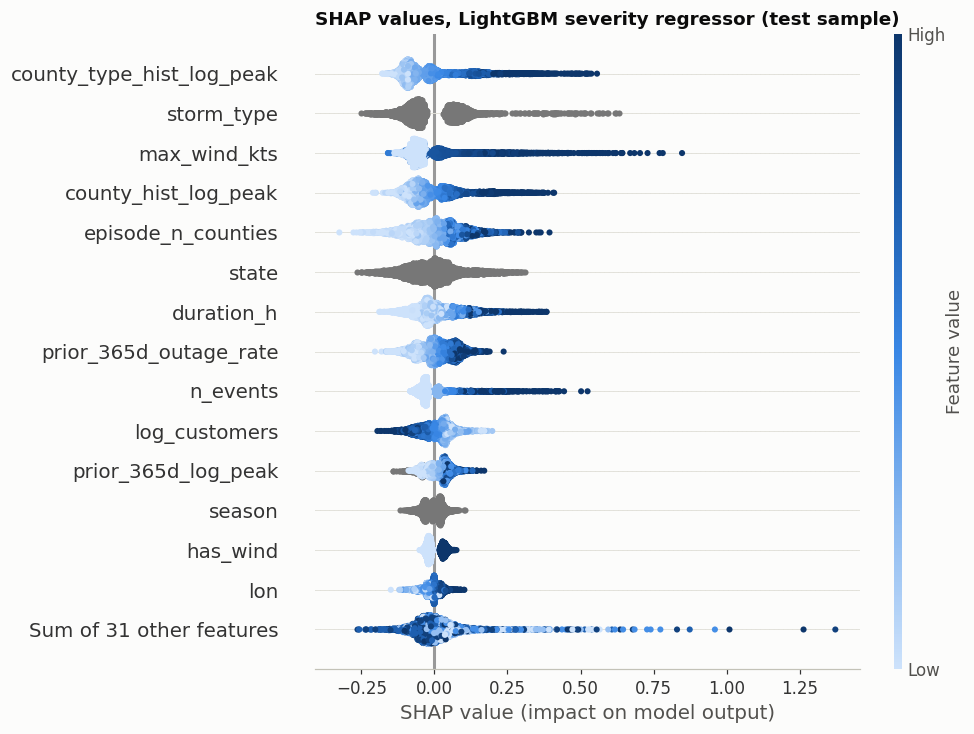

In [11]:
import shap
sv, X = S.shap_values(fit, n=5000)
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, color=viz.SEQUENTIAL_CMAP)
plt.title("SHAP values, LightGBM severity regressor (test sample)")
fig = plt.gcf(); viz.save(fig, "07_shap_summary"); fig

In [12]:
imp = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values(ascending=False)
imp.head(15).round(4).to_frame("mean |SHAP|")

,mean |SHAP|
county_type_hist_log_peak,0.0927
storm_type,0.0875
max_wind_kts,0.0817
county_hist_log_peak,0.0691
episode_n_counties,0.0678
state,0.0650
duration_h,0.0607
prior_365d_outage_rate,0.0503
n_events,0.0483
log_customers,0.0428


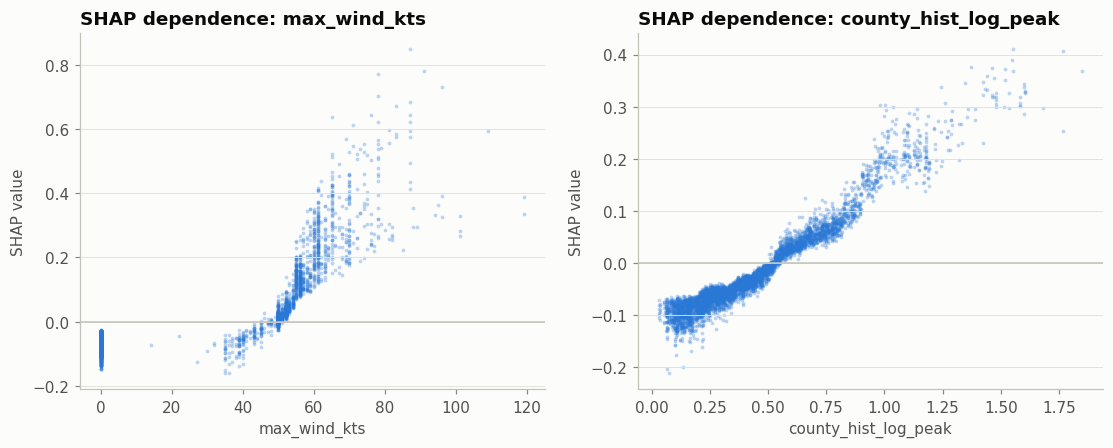

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feat in zip(axes, ["max_wind_kts", "county_hist_log_peak"]):
    j = list(X.columns).index(feat)
    ax.scatter(X[feat], sv.values[:, j], s=6, alpha=0.3, color=viz.CATEGORICAL[0], linewidths=0)
    ax.axhline(0, color=viz.AXIS, linewidth=1)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP value"); ax.set_title(f"SHAP dependence: {feat}")
viz.save(fig, "08_shap_dependence"); fig